In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv('Social_Network_Ads.csv')

In [3]:
df.head()

,User ID,Gender,Age,EstimatedSalary,Purchased
0,15624510,Male,19,19000,0
1,15810944,Male,35,20000,0
2,15668575,Female,26,43000,0
3,15603246,Female,27,57000,0
4,15804002,Male,19,76000,0


In [4]:
import seaborn as sns

In [5]:
df.drop(columns = ['Gender'],inplace = True )

In [6]:
df.head()

,User ID,Age,EstimatedSalary,Purchased
0,15624510,19,19000,0
1,15810944,35,20000,0
2,15668575,26,43000,0
3,15603246,27,57000,0
4,15804002,19,76000,0


In [7]:
df.drop(columns = ['User ID'],inplace = True)

In [8]:
df.head()

,Age,EstimatedSalary,Purchased
0,19,19000,0
1,35,20000,0
2,26,43000,0
3,27,57000,0
4,19,76000,0


<Axes: xlabel='Age', ylabel='EstimatedSalary'>

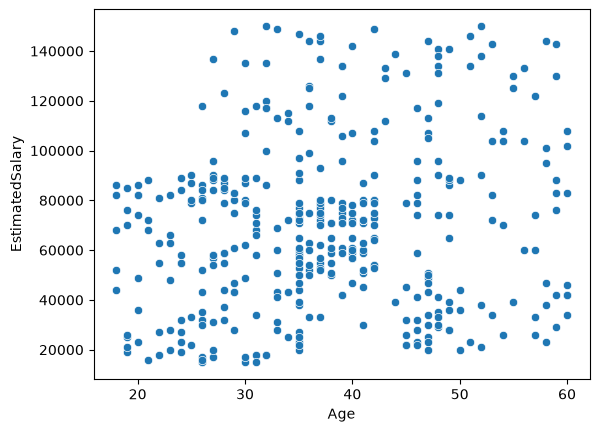

In [9]:
sns.scatterplot(
    x=df.iloc[:,0],
    y=df.iloc[:,1])

In [10]:
x = df.iloc[:,0:2]
y = df.iloc[:,-1]

In [11]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size = 0.2,random_state = 2)

In [12]:
import tensorflow as tf
from tensorflow import keras
from keras import Sequential
from keras.layers import Dense

In [13]:
model = Sequential()

model.add(Dense(128,activation='relu',input_dim=2))
model.add(Dense(1,activation='sigmoid'))

C:\Users\Hp\AppData\Roaming\Python\Python313\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [14]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │           384 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 513 (2.00 KB)

 Trainable params: 513 (2.00 KB)

 Non-trainable params: 0 (0.00 B)

In [15]:
model.compile(optimizer='Adam',loss='binary_crossentropy',metrics=['accuracy'])

In [16]:
history = model.fit(x_train,y_train,validation_data=(x_test,y_test),epochs=100)

Epoch 1/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - accuracy: 0.4406 - loss: 1254.5925 - val_accuracy: 0.6000 - val_loss: 887.3781
Epoch 2/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.5344 - loss: 464.1339 - val_accuracy: 0.4000 - val_loss: 406.9221
Epoch 3/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.4969 - loss: 264.8888 - val_accuracy: 0.6000 - val_loss: 134.0943
Epoch 4/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.4437 - loss: 141.2942 - val_accuracy: 0.6000 - val_loss: 270.3572
Epoch 5/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.5469 - loss: 124.3086 - val_accuracy: 0.6000 - val_loss: 51.0026
Epoch 6/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.5719 - loss: 44.1136 - val_accuracy: 0.4000 - val_loss: 64.6474
Epoch 7/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.4844 - loss: 48.7689 - val_accuracy: 0.3375 - val_loss: 2.4105
Epoch 8/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.4406 - loss: 64.5758 -

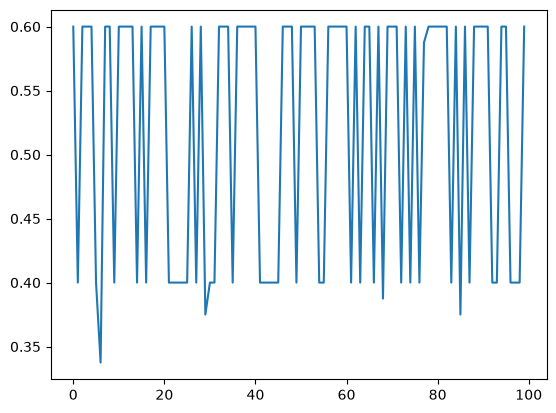

In [17]:
plt.plot(history.history['val_accuracy'])

In [18]:
# applying scaling

In [19]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()

x_train_scaled =scaler.fit_transform(x_train)
x_test_scaled =scaler.fit_transform(x_test)

In [20]:
x_test_scaled

array([[-0.74651519,  0.33929263],
       [-1.48154554, -1.59952242],
       [-0.01148485, -0.52883351],
       [-0.74651519,  0.10779233],
       [ 1.55045463, -0.03689536],
       [ 0.90730308, -1.48377227],
       [-1.29778795,  0.3103551 ],
       [-0.83839399, -1.13652181],
       [ 0.26415153, -0.32627074],
       [-0.10336364,  1.58360677],
       [-1.20590916, -1.39695965],
       [-1.38966674, -1.2812095 ],
       [-0.47087881,  1.32316893],
       [ 0.7235455 ,  0.22354248],
       [-0.19524244, -0.35520828],
       [-0.37900002, -0.81820889],
       [-1.66530312, -0.03689536],
       [ 2.10172739, -0.84714643],
       [ 1.45857584,  0.02097972],
       [-1.02215157, -0.81820889],
       [-0.01148485,  0.19460494],
       [ 0.7235455 , -0.76033381],
       [-0.6546364 , -0.26839567],
       [-0.10336364, -1.10758427],
       [-1.11403037,  0.25248002],
       [ 0.7235455 , -1.13652181],
       [ 0.7235455 , -1.42589719],
       [ 0.26415153, -0.41308336],
       [ 0.6316667 ,

<Axes: >

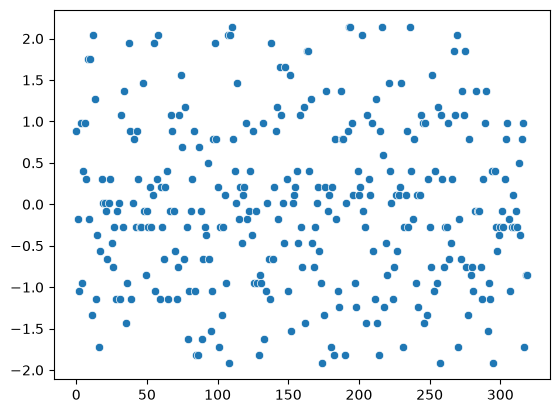

In [21]:
sns.scatterplot(x_train_scaled[:,0])

<Axes: >

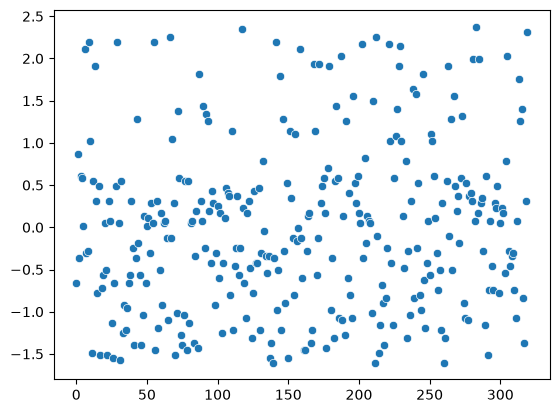

In [23]:
sns.scatterplot(x_train_scaled[:,1])